# KYRION — Figure & Table Generation (v4, final data)

Regenerates every figure and table from the **current** result CSVs. Run top to
bottom. Figures -> `paper_figures/` (300 dpi). LaTeX tables print inline.

**Fig 1** shows the four *informative* metrics (Trust, Quality, Code smells, Dead
code) — the flat all-zero hallucination panel is deliberately omitted.
**Fig 2** is the stylistic-signatures headline.

Inputs: `research/data/results_runs.csv`, `research/data/smell_breakdown.csv`.

In [1]:
import csv
from pathlib import Path
import numpy as np
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

DATA = Path("research/data")
OUT = Path("paper_figures"); OUT.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

def short(m):
    return (m.split("__")[-1].replace("-instruct","").replace("-70b","")
             .replace("-120b","").replace("-super-49b-v1","-49b").replace("-v4-flash","-flash"))

runs = list(csv.DictReader(open(DATA/"results_runs.csv")))
models = sorted({r["model"] for r in runs},
                key=lambda m:-np.mean([float(r["trust_score"]) for r in runs if r["model"]==m]))
print(f"Loaded {len(runs)} runs, {len(models)} models")
for m in models:
    print(" ", short(m), sum(1 for r in runs if r["model"]==m), "runs")

Loaded 290 runs, 5 models
  llama-3-3 59 runs
  llama-3-3-nemotron-49b 57 runs
  gpt-oss 56 runs
  deepseek-flash 57 runs
  llama-3-1 61 runs


## Helpers

In [2]:
def boot_ci(vals, n=10000, seed=42):
    rng = np.random.default_rng(seed); a = np.asarray(vals, float)
    b = rng.choice(a, size=(n, len(a)), replace=True).mean(1)
    return a.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

def vals_of(metric, model):
    return [float(r[metric]) for r in runs if r["model"]==model]

def task_means(metric):
    cell = {}
    for r in runs:
        cell.setdefault((r["model"], r["task"]), []).append(float(r[metric]))
    by = {}
    for (m,_), v in cell.items():
        by.setdefault(m, []).append(np.mean(v))
    return by

def kruskal(metric):
    by = task_means(metric); groups=[by[m] for m in models]
    allv=[v for g in groups for v in g]
    if len(set(allv))<=1: return float('nan'), float('nan')
    try: return stats.kruskal(*groups)
    except ValueError: return float('nan'), float('nan')

## FIGURE 1 — Per-model performance, four informative metrics (95% CIs)

Trust and Quality show convergence (overlapping CIs); Code smells and Dead code show
the divergence (gpt-oss lowest on smells, highest on dead code). The hallucination
panel is omitted because all values are zero.

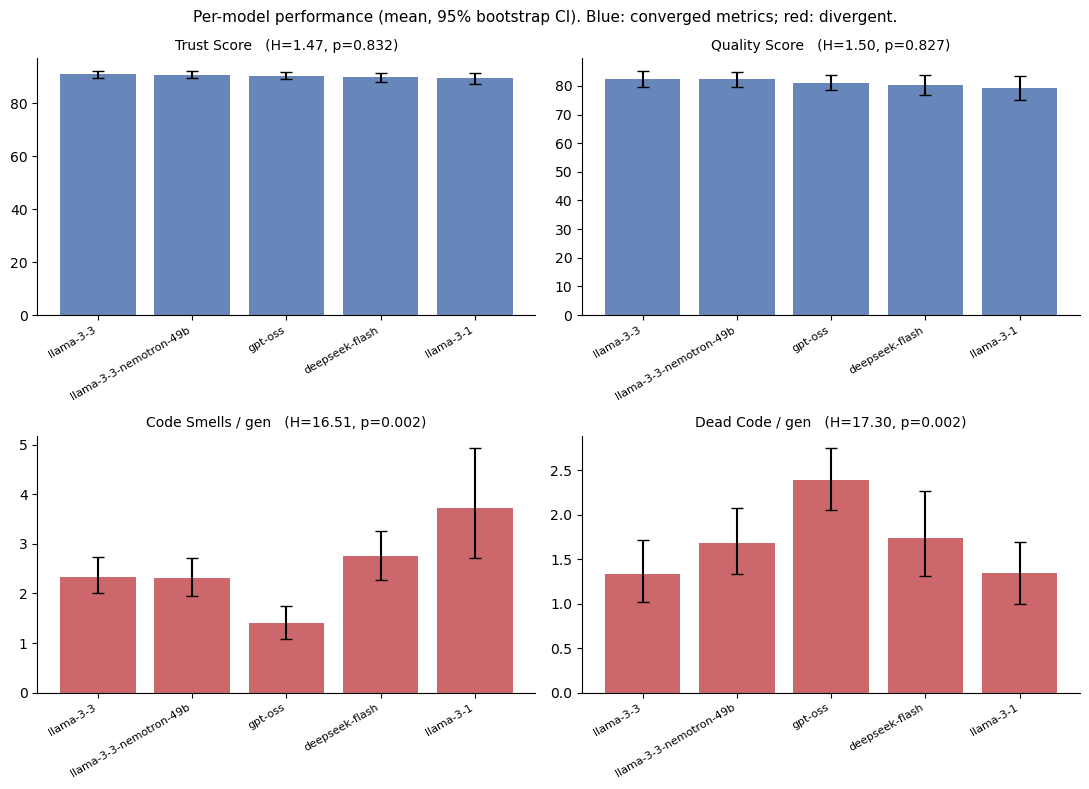

Saved fig1_performance.png


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
panels = [("trust_score","Trust Score"), ("quality_score","Quality Score"),
          ("code_smells","Code Smells / gen"), ("dead_code","Dead Code / gen")]
for ax,(mk,lab) in zip(axes.flat, panels):
    means, los, his = [], [], []
    for m in models:
        mn, lo, hi = boot_ci(vals_of(mk, m))
        means.append(mn); los.append(mn-lo); his.append(hi-mn)
    color = "#4C72B0" if mk in ("trust_score","quality_score") else "#C44E52"
    ax.bar(range(len(models)), means, yerr=[los,his], capsize=4, color=color, alpha=.85)
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels([short(m) for m in models], rotation=30, ha="right", fontsize=8)
    H,p = kruskal(mk)
    tag = f"H={H:.2f}, p={p:.3f}" if p==p else ""
    ax.set_title(f"{lab}   ({tag})", fontsize=10)
fig.suptitle("Per-model performance (mean, 95% bootstrap CI). Blue: converged metrics; red: divergent.", fontsize=11)
fig.tight_layout(); fig.savefig(OUT/"fig1_performance.png", dpi=300, bbox_inches="tight")
plt.show(); print("Saved fig1_performance.png")

## FIGURE 2 — Stylistic signatures (headline)

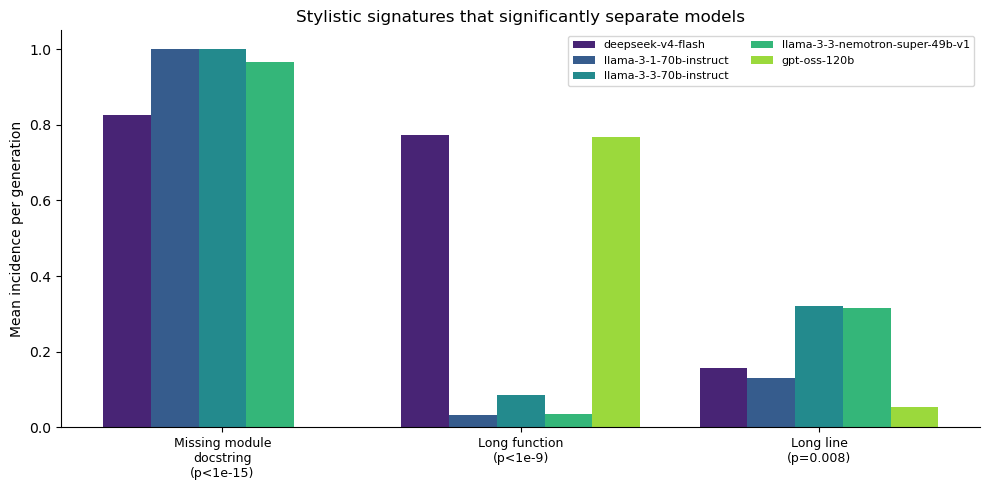

Saved fig2_signatures.png


In [5]:
sb = list(csv.DictReader(open(DATA/"smell_breakdown.csv")))
sig = ["missing_module_docstring","long_function","long_line"]
labels = ["Missing module\ndocstring\n(p<1e-15)","Long function\n(p<1e-9)","Long line\n(p=0.008)"]
mcols = [c for c in sb[0].keys() if c!="smell_type"]
fig, ax = plt.subplots(figsize=(10,5))
x = np.arange(len(sig)); w = 0.16
colors = plt.cm.viridis(np.linspace(0.1,0.85,len(mcols)))
for i, mc in enumerate(mcols):
    vals = [float(next(r[mc] for r in sb if r["smell_type"]==t)) for t in sig]
    ax.bar(x+i*w, vals, w, label=mc, color=colors[i])
ax.set_xticks(x + w*(len(mcols)-1)/2); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("Mean incidence per generation")
ax.legend(fontsize=8, ncol=2); ax.set_title("Stylistic signatures that significantly separate models")
fig.tight_layout(); fig.savefig(OUT/"fig2_signatures.png", dpi=300, bbox_inches="tight")
plt.show(); print("Saved fig2_signatures.png")

## TABLE I (LaTeX) — Master results with 95% CI

In [6]:
METRICS=[("trust_score","Trust"),("quality_score","Quality"),("code_smells","Smells"),
         ("dead_code","Dead"),("hallucination_count","Halluc")]
mm={mk:{m:np.mean(vals_of(mk,m)) for m in models} for mk,_ in METRICS}
low={"code_smells","dead_code","hallucination_count"}
print(r"\begin{table*}[t]\centering")
print(r"\caption{Per-model performance (mean; 95\% bootstrap CI). Best per column bold.}")
print(r"\label{tab:master}\begin{tabular}{l"+"c"*len(METRICS)+"}\toprule")
print("Model & "+" & ".join(l for _,l in METRICS)+r" \\ \midrule")
for m in models:
    cells=[]
    for mk,_ in METRICS:
        mn,lo,hi=boot_ci(vals_of(mk,m))
        best=(min if mk in low else max)(mm[mk].values())
        s=f"{mn:.1f}"+(f" [{lo:.1f},{hi:.1f}]" if mk in ("trust_score","quality_score") else "")
        if abs(mm[mk][m]-best)<1e-9: s=r"\textbf{"+s+"}"
        cells.append(s)
    print(f"{short(m)} & "+" & ".join(cells)+r" \\")
print(r"\bottomrule\end{tabular}\end{table*}")

\begin{table*}[t]\centering
\caption{Per-model performance (mean; 95\% bootstrap CI). Best per column bold.}
\label{tab:master}\begin{tabular}{lccccc}	oprule
Model & Trust & Quality & Smells & Dead & Halluc \\ \midrule
llama-3-3 & \textbf{91.0 [89.5,92.4]} & \textbf{82.5 [79.5,85.3]} & 2.3 & \textbf{1.3} & \textbf{0.0} \\
llama-3-3-nemotron-49b & 90.9 [89.6,92.2] & 82.3 [79.6,84.8] & 2.3 & 1.7 & \textbf{0.0} \\
gpt-oss & 90.4 [89.1,91.7] & 81.1 [78.5,83.8] & \textbf{1.4} & 2.4 & \textbf{0.0} \\
deepseek-flash & 89.9 [88.1,91.7] & 80.4 [76.7,83.8] & 2.8 & 1.7 & \textbf{0.0} \\
llama-3-1 & 89.5 [87.3,91.4] & 79.4 [75.0,83.3] & 3.7 & 1.3 & \textbf{0.0} \\
\bottomrule\end{tabular}\end{table*}


## TABLE II (LaTeX) — Omnibus with BH correction

In [7]:
ALLM=[("trust_score","Trust"),("quality_score","Quality"),("total_issues","Total issues"),
      ("security_issues","Security"),("dead_code","Dead code"),("code_smells","Code smells")]
res=[]
for mk,lab in ALLM:
    H,p=kruskal(mk); res.append([lab,H,p])
ps=[p for _,_,p in res]
order=sorted(range(len(ps)),key=lambda i:ps[i]); bh=[0]*len(ps); prev=1.0
for rank,i in enumerate(reversed(order)):
    k=len(ps)-rank; v=min(prev,ps[i]*len(ps)/k); bh[i]=v; prev=v
print(r"\begin{table}[t]\centering")
print(r"\caption{Kruskal--Wallis omnibus with Benjamini--Hochberg FDR correction.}")
print(r"\label{tab:sig}\begin{tabular}{lcccc}\toprule")
print(r"Metric & $H$ & $p_{raw}$ & $p_{BH}$ & Sig? \\ \midrule")
for (lab,H,p),b in zip(res,bh):
    sig="Yes" if b<0.05 else "No"
    print(f"{lab} & {H:.2f} & {p:.4f} & {b:.4f} & {sig} "+r"\\")
print(r"Hallucination & -- & -- & -- & No variance "+r"\\")
print(r"\bottomrule\end{tabular}\end{table}")

\begin{table}[t]\centering
\caption{Kruskal--Wallis omnibus with Benjamini--Hochberg FDR correction.}
\label{tab:sig}\begin{tabular}{lcccc}\toprule
Metric & $H$ & $p_{raw}$ & $p_{BH}$ & Sig? \\ \midrule
Trust & 1.47 & 0.8319 & 0.9619 & No \\
Quality & 1.50 & 0.8269 & 0.9619 & No \\
Total issues & 2.37 & 0.6675 & 0.9619 & No \\
Security & 0.61 & 0.9619 & 0.9619 & No \\
Dead code & 17.30 & 0.0017 & 0.0072 & Yes \\
Code smells & 16.51 & 0.0024 & 0.0072 & Yes \\
Hallucination & -- & -- & -- & No variance \\
\bottomrule\end{tabular}\end{table}
